# Explainable Credit-Risk Scorer

**Result:** On **29,946 untouched test borrowers** (**1,976 seriously delinquent**), the **Random Forest** flagged at **threshold 0.050** catches **82% of the delinquent borrowers** while flagging **31% of all applicants** (**precision 18%**).

Under the assumed **cost ratio of 20:1**, its total cost is **29,322,000 cost units** — **63% lower than approving everyone** and **48% lower than flagging everyone**.

The default **0.5 threshold** would cost **69,930,000 cost units**, **25% more than flagging everyone**.


# 1. Project Overview

## Explainable Credit Risk Scoring

**Objective:** Predict whether a borrower is likely to experience serious delinquency within the next two years.

This project treats credit risk prediction as an **imbalanced binary classification problem**, where the number of borrowers who experience serious delinquency is much smaller than the number who do not.

Instead of optimizing accuracy alone, the project focuses on **identifying high-risk borrowers, minimizing the estimated cost of prediction errors, and explaining model predictions using SHAP**.

### Key Objectives

* Perform **data exploration and preprocessing**.
* Train and compare multiple **machine learning classification models**.
* Select a decision threshold using **cost-sensitive evaluation**.
* Explain predictions using **SHAP (SHapley Additive exPlanations)**.
* Evaluate the final model on an **untouched test set**.


In [ ]:
%pip install shap

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import time

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, average_precision_score,
)

RANDOM_STATE = 42

# 2. Data Exploration and Cleaning

## Understanding the Dataset

The dataset contains borrower-related financial and credit-history information, including credit utilization, age, debt ratio, monthly income, and previous late payments.

The target variable is **`SeriousDlqin2yrs`**:

* `1` — The borrower experienced serious delinquency within two years.
* `0` — The borrower did not experience recorded serious delinquency within two years.

### Data Cleaning

The preprocessing stage addresses invalid or unusual values, caps extreme credit-utilization values, and handles missing values in selected columns.

**Why this matters:** Data quality can affect model performance and the reliability of predictions.

**Note:** In a production-quality workflow, data-dependent preprocessing such as median imputation should be fitted on the training data only to avoid data leakage.


In [ ]:
# Load the Give Me Some Credit dataset.

# The first column is only a row index, so use it as the DataFrame index
# rather than treating it as a predictive feature.

df = pd.read_csv("cs-training.csv", index_col=0)   # first column is just a row index, not a real feature

# Check the size of the dataset to see how many records and features it contains.
print(df.shape)

# First five rows
print(df.head())

# Check column names
print(df.columns.tolist())

(150000, 11)
   SeriousDlqin2yrs  RevolvingUtilizationOfUnsecuredLines  age  \
1                 1                              0.766127   45   
2                 0                              0.957151   40   
3                 0                              0.658180   38   
4                 0                              0.233810   30   
5                 0                              0.907239   49   

   NumberOfTime30-59DaysPastDueNotWorse  DebtRatio  MonthlyIncome  \
1                                     2   0.802982         9120.0   
2                                     0   0.121876         2600.0   
3                                     1   0.085113         3042.0   
4                                     0   0.036050         3300.0   
5                                     1   0.024926        63588.0   

   NumberOfOpenCreditLinesAndLoans  NumberOfTimes90DaysLate  \
1                               13                        0   
2                                4               

In [ ]:
# Check the number of missing values in each column.

print(df.isna().sum())

# Check the distribution of the target variable.

print(df["SeriousDlqin2yrs"].value_counts())
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))

# The target is highly imbalanced, with far fewer customers in the default class.

# Statistics Summary
print(df.describe())


SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64
       SeriousDlqin2yrs  RevolvingUtilizationOfUnsecuredLines            age  \
count     150000.000000                         150000.000000  150000.000000   
mean           0.066840                              6.048438      52.295207   
std            0.249746                            249.755371      14.771866   
min            0.0

In [ ]:
# Investigating unusual credit-utilization values

print((df["age"] == 0).sum())
print(df[df["age"] == 0])

print((df["RevolvingUtilizationOfUnsecuredLines"] > 2).sum())
print(df["RevolvingUtilizationOfUnsecuredLines"].sort_values(ascending=False).head(10))

print((df["NumberOfTimes90DaysLate"] == 98).sum())
print(df["NumberOfTimes90DaysLate"].value_counts().sort_index(ascending=False).head(10))

print(((df["NumberOfTime30-59DaysPastDueNotWorse"] >= 96) &
       (df["NumberOfTimes90DaysLate"] >= 96) &
       (df["NumberOfTime60-89DaysPastDueNotWorse"] >= 96)).sum())

1
       SeriousDlqin2yrs  RevolvingUtilizationOfUnsecuredLines  age  \
65696                 0                                   1.0    0   

       NumberOfTime30-59DaysPastDueNotWorse  DebtRatio  MonthlyIncome  \
65696                                     1   0.436927         6000.0   

       NumberOfOpenCreditLinesAndLoans  NumberOfTimes90DaysLate  \
65696                                6                        0   

       NumberRealEstateLoansOrLines  NumberOfTime60-89DaysPastDueNotWorse  \
65696                             2                                     0   

       NumberOfDependents  
65696                 2.0  
371
85490     50708.0
31415     29110.0
16957     22198.0
149161    22000.0
149280    20514.0
117316    18300.0
21979     17441.0
124534    13930.0
72593     13498.0
71706     13400.0
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64
264
NumberOfTimes90DaysLate
98    264
96      5
17      1
15      2
14      2
13      4
12      2
11      5
10      8
9  

In [ ]:
income_missing = df["MonthlyIncome"].isna()
debt_extreme = df["DebtRatio"] > 10

print("Rows by (income missing) x (DebtRatio > 10):")
print(pd.crosstab(income_missing, debt_extreme,
                  rownames=["income missing"], colnames=["DebtRatio > 10"]))

print("\nDefault rate and group size:")
print(df.groupby([income_missing.rename("income missing"),
                  debt_extreme.rename("DebtRatio > 10")])["SeriousDlqin2yrs"]
        .agg(["mean", "size"]))

print("\nDebtRatio when income is missing:")
print(df.loc[income_missing, "DebtRatio"].describe())
print("\nDebtRatio when income is present:")
print(df.loc[~income_missing, "DebtRatio"].describe())

Rows by (income missing) x (DebtRatio > 10):
DebtRatio > 10   False  True 
income missing               
False           118163   2106
True              2960  26771

Default rate and group size:
                                   mean    size
income missing DebtRatio > 10                  
False          False           0.070005  118163
               True            0.040361    2106
True           False           0.048986    2960
               True            0.056927   26771

DebtRatio when income is missing:
count     29731.000000
mean       1673.396556
std        4248.372895
min           0.000000
25%         123.000000
50%        1159.000000
75%        2382.000000
max      329664.000000
Name: DebtRatio, dtype: float64

DebtRatio when income is present:
count    120269.000000
mean         26.598777
std         424.446457
min           0.000000
25%           0.143388
50%           0.296023
75%           0.482559
max       61106.500000
Name: DebtRatio, dtype: float64


In [ ]:
df = df[df["age"] > 0].copy()
df = df[df["NumberOfTimes90DaysLate"] < 96].copy()
df["RevolvingUtilizationOfUnsecuredLines"] = df["RevolvingUtilizationOfUnsecuredLines"].clip(upper=2)

print(df.shape)   # 150,000 - 1 - 269 = 149,730 rows expected
print(df.isna().sum())   # the two columns with missing values are filled later, inside the pipeline

(149730, 11)
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29610
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3893
dtype: int64


## Assumptions and settings

These numbers are **assumptions**, not facts from the data, so they are defined in one place.

- `COST_FN = 40,000`: cost of missing a borrower who becomes seriously delinquent.
- `COST_FP = 2,000`: cost of flagging a borrower who would have been fine (review effort, lost business).
- That is a 20 : 1 ratio, which is a reasonable-sounding guess, not a measurement. Section 8 re-runs the analysis at other ratios.
- `TOLERANCE = 0.02`: the cost curve is flat near its minimum (see Section 7), so thresholds within 2% of the cheapest cost are treated as equally good, and the strictest of them is chosen. Set it to 0 to use the exact cheapest threshold.

In [ ]:
COST_FP = 2_000      # cost units: wrongly flagging a borrower who would have been fine
COST_FN = 40_000     # cost units: missing a borrower who becomes seriously delinquent
TOLERANCE = 0.02     # thresholds within 2% of the cheapest cost count as equally good
THRESHOLDS = np.round(np.arange(0.005, 0.505, 0.005), 3)

# 3. Data Splitting and Baselines

## Train, Validation, and Test Sets

The dataset is divided into three subsets using **stratified sampling** to preserve the proportion of delinquent and non-delinquent borrowers.

* **Training set:** Used to train models and tune hyperparameters.
* **Validation set:** Used to compare models and select the decision threshold.
* **Test set:** Used only for the final evaluation.

### Why Is Accuracy Not Enough?

Because the target is imbalanced, a model can achieve high accuracy while missing many borrowers who actually experience delinquency.

Therefore, the evaluation considers:

* **Precision:** How many borrowers flagged as high risk actually experienced delinquency?
* **Recall:** How many actual delinquent borrowers did the model identify?
* **F1-score:** The harmonic mean of precision and recall.
* **ROC-AUC:** How well the model ranks positive cases above negative cases.
* **PR-AUC:** How well the model balances precision and recall, particularly for the minority class.

**For this project, recall is especially important because missing a high-risk borrower can be costly.**


In [ ]:
X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=RANDOM_STATE, stratify=y_temp
)

for name, part in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11}{len(part):>8,} rows | positive rate {part.mean():.4f}")

Train        89,838 rows | positive rate 0.0660
Validation   29,946 rows | positive rate 0.0660
Test         29,946 rows | positive rate 0.0660


In [ ]:
def confusion_at(y_true, prob, threshold):
    """Confusion-matrix counts when everyone with prob >= threshold is flagged."""
    pred = np.asarray(prob) >= threshold
    actual = np.asarray(y_true).astype(bool)
    tp = int((pred & actual).sum())
    fp = int((pred & ~actual).sum())
    fn = int((~pred & actual).sum())
    tn = int((~pred & ~actual).sum())
    return tn, fp, fn, tp


def cost_of(y_true, prob, threshold, cost_fn=COST_FN, cost_fp=COST_FP):
    tn, fp, fn, tp = confusion_at(y_true, prob, threshold)
    return fn * cost_fn + fp * cost_fp


def threshold_table(y_true, prob, cost_fn=COST_FN, cost_fp=COST_FP, thresholds=THRESHOLDS):
    n = len(y_true)
    rows = []
    for t in thresholds:
        tn, fp, fn, tp = confusion_at(y_true, prob, t)
        rows.append({
            "Threshold": t,
            "Flagged %": 100 * (tp + fp) / n,
            "Precision": tp / (tp + fp) if (tp + fp) else 0.0,
            "Recall": tp / (tp + fn) if (tp + fn) else 0.0,
            "FP": fp,
            "FN": fn,
            "Total cost": fn * cost_fn + fp * cost_fp,
        })
    return pd.DataFrame(rows)


# Baselines on the validation set
n_val = len(y_val)
n_bad_val = int(y_val.sum())
n_good_val = n_val - n_bad_val

approve_all_cost = n_bad_val * COST_FN
flag_all_cost = n_good_val * COST_FP

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
baseline_prob = dummy.predict_proba(X_val)[:, 1]

print(f"Validation set: {n_val:,} borrowers, {n_bad_val:,} positives ({n_bad_val / n_val:.1%})")
print(f"Approve everyone: cost {approve_all_cost:>12,}")
print(f"Flag everyone:    cost {flag_all_cost:>12,}")
print(f"Dummy model:      ROC-AUC {roc_auc_score(y_val, baseline_prob):.3f} | "
      f"PR-AUC {average_precision_score(y_val, baseline_prob):.3f}")

Validation set: 29,946 borrowers, 1,976 positives (6.6%)
Approve everyone: cost   79,040,000
Flag everyone:    cost   55,940,000
Dummy model:      ROC-AUC 0.500 | PR-AUC 0.066


# 4. Model Training and Comparison

## Candidate Models

Four classification algorithms are evaluated:

1. **Logistic Regression:** Provides a relatively simple baseline and estimates a linear relationship between features and log-odds.
2. **Decision Tree:** Learns decision rules and captures nonlinear patterns.
3. **Random Forest:** Combines multiple decision trees to improve predictive performance and reduce variance.
4. **Gradient Boosting:** Builds trees sequentially, with each stage attempting to improve on earlier predictions.

### Hyperparameter Tuning

**GridSearchCV with cross-validation** is used to evaluate different hyperparameter combinations.

Cross-validation provides a more reliable estimate of model performance than relying on a single training split.

The models are compared using metrics relevant to the imbalanced classification problem. **The final model should be selected based on validation results and the project's risk objectives, not accuracy alone.**


In [ ]:
def make_pipeline(model, log_transform=False, scale=False):
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if log_transform:
        steps.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)


# name -> (pipeline, parameter grid, n_jobs for GridSearchCV)
candidates = {
    "Logistic Regression": (
        make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                      log_transform=True, scale=True),
        {"model__C": [0.01, 0.1, 1, 10]},
        -1,
    ),
    "Decision Tree": (
        make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        {"model__max_depth": [3, 4, 5, 6, 8, 10],
         "model__min_samples_leaf": [1, 20, 100]},
        -1,
    ),
    "Random Forest": (
        make_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
        {"model__max_depth": [6, 10, 14, 20],
         "model__min_samples_leaf": [5, 20, 50]},
        1,   # the forest already uses all cores
    ),
    "Gradient Boosting": (
        make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
        {"model__n_estimators": [100, 200],
         "model__learning_rate": [0.05, 0.1],
         "model__max_depth": [2, 3]},
        -1,
    ),
}

searches = {}
for name, (pipe, grid, jobs) in candidates.items():
    start = time.time()
    search = GridSearchCV(pipe, grid, cv=3, scoring="average_precision", n_jobs=jobs)
    search.fit(X_train, y_train)
    searches[name] = search

    print(f"{name}: best CV PR-AUC {search.best_score_:.4f} | "
          f"best settings {search.best_params_} | {time.time() - start:.0f}s")
    for param, values in grid.items():
        best_value = search.best_params_[param]
        if len(values) > 1 and best_value in (min(values), max(values)):
            print(f"    Note: {param} = {best_value} is at the edge of its grid {values}; "
                  f"consider extending the grid.")

Logistic Regression: best CV PR-AUC 0.3694 | best settings {'model__C': 0.01} | 7s
    Note: model__C = 0.01 is at the edge of its grid [0.01, 0.1, 1, 10]; consider extending the grid.
Decision Tree: best CV PR-AUC 0.3482 | best settings {'model__max_depth': 10, 'model__min_samples_leaf': 100} | 33s
    Note: model__max_depth = 10 is at the edge of its grid [3, 4, 5, 6, 8, 10]; consider extending the grid.
    Note: model__min_samples_leaf = 100 is at the edge of its grid [1, 20, 100]; consider extending the grid.
Random Forest: best CV PR-AUC 0.3834 | best settings {'model__max_depth': 14, 'model__min_samples_leaf': 20} | 505s
Gradient Boosting: best CV PR-AUC 0.3830 | best settings {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200} | 351s
    Note: model__n_estimators = 200 is at the edge of its grid [100, 200]; consider extending the grid.
    Note: model__learning_rate = 0.05 is at the edge of its grid [0.05, 0.1]; consider extending the grid.
    Not

# 5. Cost-Sensitive Threshold Selection

## Why Adjust the Decision Threshold?

A classification model produces a probability or risk score. A **decision threshold** determines when a borrower is classified as high risk.

The default threshold is commonly `0.50`, but this may not be suitable for an imbalanced credit-risk problem.

* **Lower threshold:** Usually increases recall but can also increase false positives.
* **Higher threshold:** Usually reduces false positives but may miss more delinquent borrowers.

## Defining the Cost Assumptions

This project assigns hypothetical costs to two types of prediction errors:

* **False Negative (FN):** A borrower experiences delinquency, but the model predicts low risk.
* **False Positive (FP):** A borrower does not experience delinquency, but the model predicts high risk.

The estimated total cost is calculated as:

**Total Cost = (FN × Cost per FN) + (FP × Cost per FP)**

The assumed cost of a false negative is higher than the cost of a false positive.

**Important:** These are illustrative cost assumptions, not verified financial losses from a real lender.

## Selecting the Threshold

Candidate thresholds are compared on the **validation set**. The selected threshold aims to minimize the estimated cost under the chosen assumptions.

After selection, the model and threshold are fixed before evaluating the test set. **The test set must not be used to choose the threshold**, because doing so can produce an overly optimistic evaluation.


In [ ]:
DUMMY_NAME = "Dummy (always predicts base rate)"

rows = []
val_probs = {}
for name, search in searches.items():
    prob = search.best_estimator_.predict_proba(X_val)[:, 1]
    val_probs[name] = prob
    table = threshold_table(y_val, prob)
    cheapest = table.loc[table["Total cost"].idxmin()]
    rows.append({
        "Model": name,
        "CV PR-AUC (train)": search.best_score_,
        "Val ROC-AUC": roc_auc_score(y_val, prob),
        "Val PR-AUC": average_precision_score(y_val, prob),
        "Cheapest threshold": cheapest["Threshold"],
        "Flagged %": cheapest["Flagged %"],
        "Recall": cheapest["Recall"],
        "Precision": cheapest["Precision"],
        "Cost at cheapest": int(cheapest["Total cost"]),
    })

rows.append({
    "Model": DUMMY_NAME,
    "CV PR-AUC (train)": np.nan,
    "Val ROC-AUC": roc_auc_score(y_val, baseline_prob),
    "Val PR-AUC": average_precision_score(y_val, baseline_prob),
    "Cheapest threshold": np.nan,
    "Flagged %": np.nan,
    "Recall": np.nan,
    "Precision": np.nan,
    "Cost at cheapest": int(min(approve_all_cost, flag_all_cost)),
})

comparison = pd.DataFrame(rows).sort_values("Cost at cheapest").reset_index(drop=True)
comparison["Saving vs approve-all (%)"] = 100 * (1 - comparison["Cost at cheapest"] / approve_all_cost)
display(comparison.round(4))

real_models = comparison[comparison["Model"] != DUMMY_NAME].reset_index(drop=True)
deployed_name = real_models.loc[0, "Model"]
deployed_model = searches[deployed_name].best_estimator_
val_prob = val_probs[deployed_name]

gap = 100 * (real_models.loc[1, "Cost at cheapest"] / real_models.loc[0, "Cost at cheapest"] - 1)
print(f"\nDeployed model: {deployed_name}")
print(f"Runner-up ({real_models.loc[1, 'Model']}) costs {gap:.1f}% more on validation.")
if gap < 3:
    print("The gap is small; the top models are effectively tied on this validation set.")

,Model,CV PR-AUC (train),Val ROC-AUC,Val PR-AUC,Cheapest threshold,Flagged %,Recall,Precision,Cost at cheapest,Saving vs approve-all (%)
0,Random Forest,0.3834,0.8733,0.4256,0.045,32.4851,0.8598,0.1747,27138000,65.6655
1,Gradient Boosting,0.3830,0.8713,0.4194,0.045,31.7705,0.8497,0.1765,27550000,65.1442
2,Decision Tree,0.3482,0.8565,0.3950,0.040,31.8473,0.8360,0.1732,28730000,63.6513
3,Logistic Regression,0.3694,0.8614,0.4063,0.045,33.8276,0.8462,0.1651,29076000,63.2136
4,Dummy (always predicts base rate),NaN,0.5000,0.0660,NaN,NaN,NaN,NaN,55940000,29.2257



Deployed model: Random Forest
Runner-up (Gradient Boosting) costs 1.5% more on validation.
The gap is small; the top models are effectively tied on this validation set.


Cheapest threshold:      0.045 (cost 27,138,000, flags 32.5% of applicants)
Near-optimal range:      0.040 to 0.050 (within 2% of the cheapest cost)
Chosen final threshold:  0.050 (cost 27,410,000, flags 30.3%, recall 0.841, precision 0.183)

Thresholds within tolerance of the cheapest cost:


,Threshold,Flagged %,Precision,Recall,FP,FN,Total cost,Cost vs cheapest (%)
7,0.040,34.816,0.165,0.870,8706,256,27652000,1.894
8,0.045,32.485,0.175,0.860,8029,277,27138000,0.000
9,0.050,30.345,0.183,0.841,7425,314,27410000,1.002


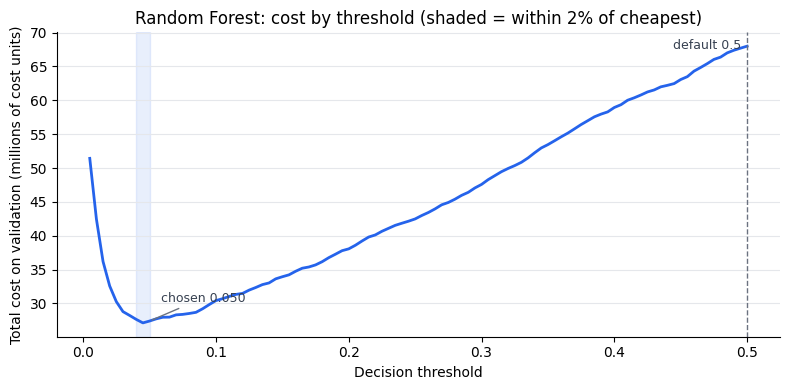

In [ ]:
val_table = threshold_table(y_val, val_prob)

min_cost = val_table["Total cost"].min()
val_table["Cost vs cheapest (%)"] = 100 * (val_table["Total cost"] / min_cost - 1)

cheapest_row = val_table.loc[val_table["Total cost"].idxmin()]
near_optimal = val_table[val_table["Total cost"] <= (1 + TOLERANCE) * min_cost]
final_threshold = float(near_optimal["Threshold"].max())
final_row = val_table.loc[np.isclose(val_table["Threshold"], final_threshold)].iloc[0]

print(f"Cheapest threshold:      {cheapest_row['Threshold']:.3f} "
      f"(cost {cheapest_row['Total cost']:,.0f}, flags {cheapest_row['Flagged %']:.1f}% of applicants)")
print(f"Near-optimal range:      {near_optimal['Threshold'].min():.3f} to {near_optimal['Threshold'].max():.3f} "
      f"(within {TOLERANCE:.0%} of the cheapest cost)")
print(f"Chosen final threshold:  {final_threshold:.3f} "
      f"(cost {final_row['Total cost']:,.0f}, flags {final_row['Flagged %']:.1f}%, "
      f"recall {final_row['Recall']:.3f}, precision {final_row['Precision']:.3f})")

print("\nThresholds within tolerance of the cheapest cost:")
display(near_optimal.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(val_table["Threshold"], val_table["Total cost"] / 1e6, color="#2563eb", linewidth=2)
ax.axvspan(near_optimal["Threshold"].min(), near_optimal["Threshold"].max(),
           color="#2563eb", alpha=0.10)
ax.axvline(0.5, color="#6b7280", linestyle="--", linewidth=1)
ax.annotate("default 0.5", xy=(0.5, ax.get_ylim()[1]), xytext=(-4, -12),
            textcoords="offset points", ha="right", color="#374151", fontsize=9)
ax.annotate(f"chosen {final_threshold:.3f}",
            xy=(final_threshold, final_row["Total cost"] / 1e6),
            xytext=(8, 14), textcoords="offset points", color="#374151", fontsize=9,
            arrowprops=dict(arrowstyle="-", color="#6b7280"))
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Total cost on validation (millions of cost units)")
ax.set_title(f"{deployed_name}: cost by threshold (shaded = within {TOLERANCE:.0%} of cheapest)")
ax.grid(axis="y", color="#e5e7eb", linewidth=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
capacity_rows = []
for capacity in [0.10, 0.15, 0.20, 0.30, 0.40]:
    t = float(np.quantile(val_prob, 1 - capacity))
    tn, fp, fn, tp = confusion_at(y_val, val_prob, t)
    capacity_rows.append({
        "Review capacity": f"{capacity:.0%}",
        "Threshold": round(t, 4),
        "Flagged %": 100 * (tp + fp) / len(y_val),
        "Recall": tp / (tp + fn),
        "Precision": tp / (tp + fp),
        "Total cost": fn * COST_FN + fp * COST_FP,
    })
capacity_table = pd.DataFrame(capacity_rows)
capacity_table["Cost vs cheapest (%)"] = 100 * (capacity_table["Total cost"] / min_cost - 1)
display(capacity_table.round(3))

,Review capacity,Threshold,Flagged %,Recall,Precision,Total cost,Cost vs cheapest (%)
0,10%,0.182,10.001,0.586,0.386,36436000,34.262
1,15%,0.121,15.000,0.680,0.299,31618000,16.508
2,20%,0.089,20.003,0.747,0.246,29028000,6.964
3,30%,0.051,30.001,0.838,0.184,27456000,1.172
4,40%,0.032,40.002,0.899,0.148,28406000,4.672


In [ ]:
sensitivity_rows = []
for ratio in [5, 10, 20, 40]:
    cost_fn_r = ratio * COST_FP
    table_r = threshold_table(y_val, val_prob, cost_fn=cost_fn_r, cost_fp=COST_FP)
    best_r = table_r.loc[table_r["Total cost"].idxmin()]
    cost_with_chosen = table_r.loc[np.isclose(table_r["Threshold"], final_threshold), "Total cost"].iloc[0]
    sensitivity_rows.append({
        "FN : FP cost ratio": f"{ratio} : 1",
        "Cheapest threshold": best_r["Threshold"],
        "Flagged %": best_r["Flagged %"],
        "Recall": best_r["Recall"],
        "Cost at cheapest": int(best_r["Total cost"]),
        "Cost at chosen threshold": int(cost_with_chosen),
        "Regret (%)": 100 * (cost_with_chosen / best_r["Total cost"] - 1),
    })
display(pd.DataFrame(sensitivity_rows).round(3))

,FN : FP cost ratio,Cheapest threshold,Flagged %,Recall,Cost at cheapest,Cost at chosen threshold,Regret (%)
0,5 : 1,0.180,10.122,0.590,11842000,17990000,51.917
1,10 : 1,0.120,15.131,0.682,18926000,21130000,11.645
2,20 : 1,0.045,32.485,0.860,27138000,27410000,1.002
3,40 : 1,0.030,41.575,0.905,36282000,39970000,10.165


# 6. SHAP Explainability

## Understanding Model Predictions

**SHAP (SHapley Additive exPlanations)** helps explain how individual features influence a model's predictions.

Two types of explanations are useful:

* **Global explanation:** Identifies which features have the greatest overall influence across multiple predictions.
* **Local explanation:** Shows how features contribute to a specific borrower's prediction.

Features such as credit utilization, previous late payments, age, debt ratio, and income may influence the predicted risk.

### Why SHAP Matters

In credit-risk applications, a prediction alone may not explain why a borrower was classified as high risk. SHAP provides additional insight into the model's reasoning.

**SHAP explains model behavior; it does not prove causation, guarantee prediction correctness, or establish that a feature is fair to use.**


Mean |SHAP| per feature (larger = bigger average influence on predictions):
RevolvingUtilizationOfUnsecuredLines    0.0325
NumberOfTimes90DaysLate                 0.0271
NumberOfTime30-59DaysPastDueNotWorse    0.0206
NumberOfTime60-89DaysPastDueNotWorse    0.0137
age                                     0.0093
DebtRatio                               0.0056
NumberOfOpenCreditLinesAndLoans         0.0046
MonthlyIncome                           0.0041
NumberRealEstateLoansOrLines            0.0031
NumberOfDependents                      0.0020
missingindicator_MonthlyIncome          0.0007
missingindicator_NumberOfDependents     0.0000
dtype: float64


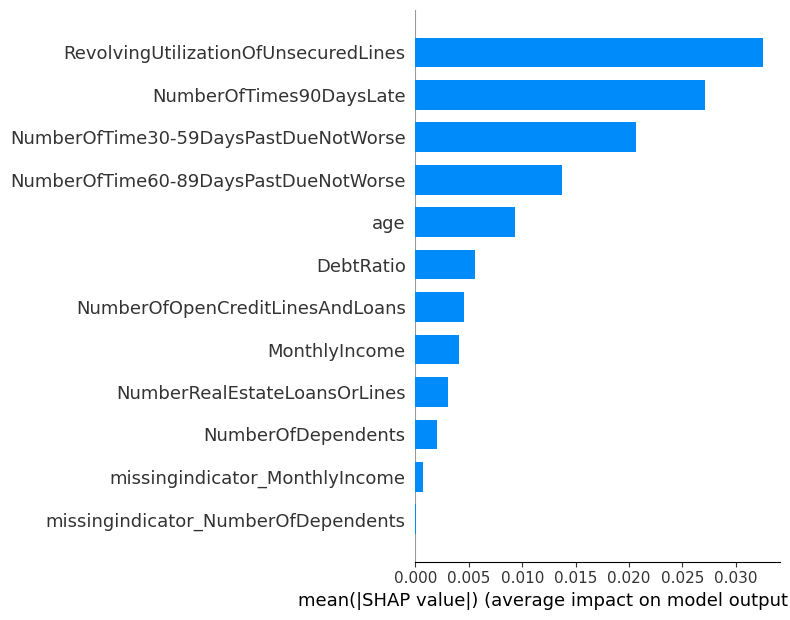

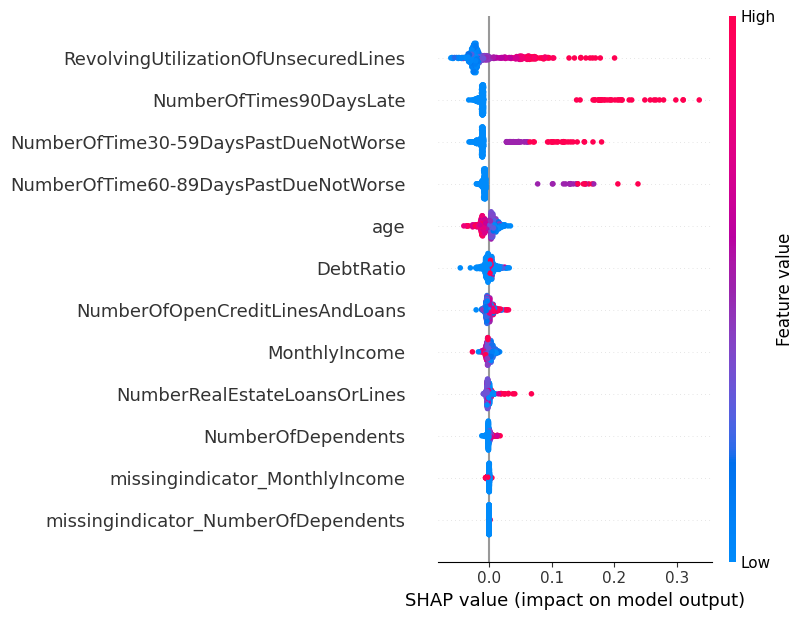

In [ ]:
final_estimator = deployed_model.named_steps["model"]
preprocess = deployed_model[:-1]

# A sample of validation applicants to explain, passed through the same preprocessing as the model
X_shap = X_val.sample(n=min(500, len(X_val)), random_state=RANDOM_STATE)
X_shap_t = pd.DataFrame(
    preprocess.transform(X_shap),
    columns=preprocess.get_feature_names_out(),
    index=X_shap.index,
)

if isinstance(final_estimator, LogisticRegression):
    explainer = shap.LinearExplainer(final_estimator, X_shap_t)
else:
    explainer = shap.TreeExplainer(final_estimator)

shap_values = explainer.shap_values(X_shap_t)


def positive_class_values(values):
    """Different SHAP versions and models return different shapes; keep the positive class."""
    if isinstance(values, list):
        return values[1]
    values = np.asarray(values)
    return values[:, :, 1] if values.ndim == 3 else values


shap_default = positive_class_values(shap_values)

mean_abs_shap = (
    pd.Series(np.abs(shap_default).mean(axis=0), index=X_shap_t.columns)
    .sort_values(ascending=False)
)
print("Mean |SHAP| per feature (larger = bigger average influence on predictions):")
print(mean_abs_shap.round(4))

shap.summary_plot(shap_default, X_shap_t, plot_type="bar")
shap.summary_plot(shap_default, X_shap_t)

Predicted probability of serious delinquency: 0.7398

Applicant's original features:


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
128241,1.092134,51,6,0.740741,3914.0,7,5,2,0,3.0


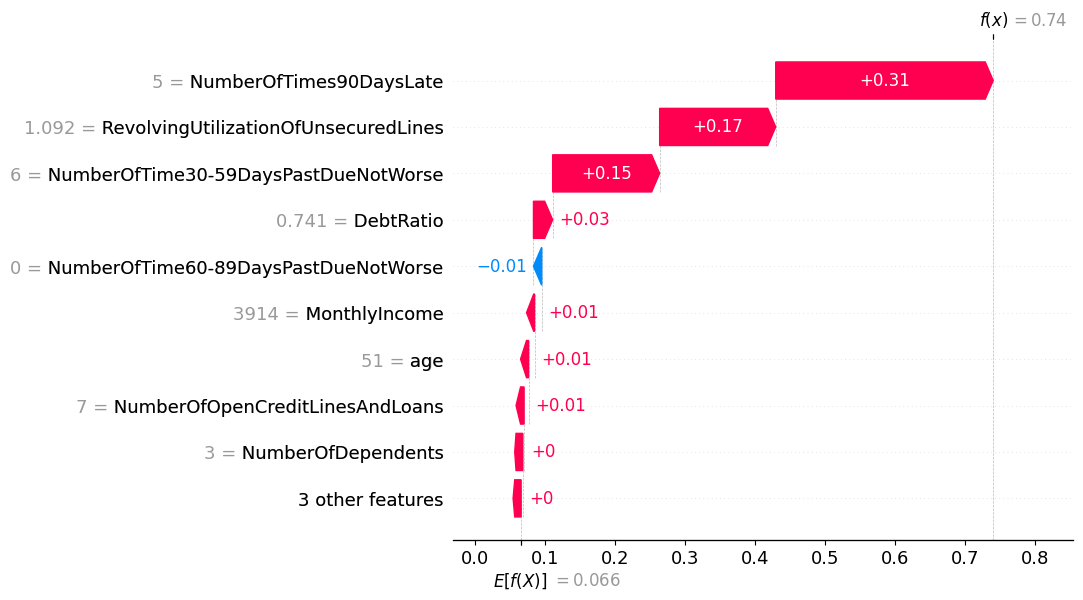

In [ ]:
# Explain the single highest-risk applicant in the sample
sample_prob = deployed_model.predict_proba(X_shap)[:, 1]
applicant_pos = int(sample_prob.argmax())

print("Predicted probability of serious delinquency:", round(float(sample_prob[applicant_pos]), 4))
print("\nApplicant's original features:")
display(X_shap.iloc[[applicant_pos]])

base_value = np.atleast_1d(explainer.expected_value)
base_value = float(base_value[1]) if base_value.size > 1 else float(base_value[0])

explanation = shap.Explanation(
    values=shap_default[applicant_pos],
    base_values=base_value,
    data=X_shap_t.iloc[applicant_pos].values,
    feature_names=X_shap_t.columns.tolist(),
)
shap.plots.waterfall(explanation)

# 7. Final Test Evaluation

## Evaluating the Selected Model

After selecting the model and decision threshold using the training and validation stages, the final configuration is evaluated on the **untouched test set**.

The final evaluation includes:

* **Precision, recall, F1-score, and accuracy**
* **ROC-AUC and PR-AUC**
* **Confusion matrix** to examine false positives and false negatives
* **Estimated total cost** under the project's stated assumptions

The confusion matrix helps identify the types of mistakes made by the model, while the cost calculation connects those mistakes to the project's assumed business priorities.

### Final Results

Report the actual test metrics produced by the completed notebook here. Do not substitute validation metrics for test metrics.

**The final test results provide an estimate of performance on held-out data; they do not guarantee performance in a real lending environment.**


In [ ]:
test_prob = deployed_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= final_threshold).astype(int)
tn, fp, fn, tp = confusion_at(y_test, test_prob, final_threshold)

print(f"Model: {deployed_name} | threshold {final_threshold:.3f}\n")
print(f"ROC-AUC:   {roc_auc_score(y_test, test_prob):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, test_prob):.4f}  "
      f"(a model with no skill scores {y_test.mean():.4f})")
print(f"Accuracy:  {accuracy_score(y_test, test_pred):.4f}   <- misleading with imbalanced classes")
print(f"Precision: {precision_score(y_test, test_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, test_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, test_pred, zero_division=0):.4f}")

print("\nConfusion matrix:")
print(f"True negatives:  {tn:>7,}   False positives: {fp:>7,}")
print(f"False negatives: {fn:>7,}   True positives:  {tp:>7,}")

print("\nClassification report:")
print(classification_report(y_test, test_pred, zero_division=0))

Model: Random Forest | threshold 0.050

ROC-AUC:   0.8572
PR-AUC:    0.3914  (a model with no skill scores 0.0660)
Accuracy:  0.7363   <- misleading with imbalanced classes
Precision: 0.1768
Recall:    0.8198
F1-score:  0.2909

Confusion matrix:
True negatives:   20,429   False positives:   7,541
False negatives:     356   True positives:    1,620

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.73      0.84     27970
           1       0.18      0.82      0.29      1976

    accuracy                           0.74     29946
   macro avg       0.58      0.78      0.56     29946
weighted avg       0.93      0.74      0.80     29946



In [ ]:
n_test = len(y_test)
n_bad_test = int(y_test.sum())
n_good_test = n_test - n_bad_test

approve_all_test = n_bad_test * COST_FN
flag_all_test = n_good_test * COST_FP
model_test_cost = fn * COST_FN + fp * COST_FP
default_threshold_cost = cost_of(y_test, test_prob, 0.5)

summary = pd.DataFrame({
    "Strategy": [
        "Approve everyone",
        "Flag everyone",
        f"{deployed_name} at the default 0.5 threshold",
        f"{deployed_name} at threshold {final_threshold:.3f}",
    ],
    "Total cost": [approve_all_test, flag_all_test, default_threshold_cost, model_test_cost],
})
summary["Saving vs approve-all (%)"] = 100 * (1 - summary["Total cost"] / approve_all_test)
summary["Saving vs flag-all (%)"] = 100 * (1 - summary["Total cost"] / flag_all_test)
display(summary.round(1))

# Same-size comparison of validation vs test cost, per 1,000 applicants
val_per_1000 = 1000 * final_row["Total cost"] / len(y_val)
test_per_1000 = 1000 * model_test_cost / n_test
print(f"\nCost per 1,000 applicants: validation {val_per_1000:,.0f} vs test {test_per_1000:,.0f} "
      f"({100 * (test_per_1000 / val_per_1000 - 1):+.1f}%). "
      f"A small rise is expected because the threshold was picked on the validation set.")

,Strategy,Total cost,Saving vs approve-all (%),Saving vs flag-all (%)
0,Approve everyone,79040000,0.0,-41.3
1,Flag everyone,55940000,29.2,0.0
2,Random Forest at the default 0.5 threshold,69930000,11.5,-25.0
3,Random Forest at threshold 0.050,29322000,62.9,47.6



Cost per 1,000 applicants: validation 915,314 vs test 979,162 (+7.0%). A small rise is expected because the threshold was picked on the validation set.


In [ ]:
saving_approve = 100 * (1 - model_test_cost / approve_all_test)
saving_flag = 100 * (1 - model_test_cost / flag_all_test)
default_vs_flag = 100 * (default_threshold_cost / flag_all_test - 1)

print("RESULTS SENTENCE (paste into the top of the notebook and the README):\n")
print(
    f"On {n_test:,} untouched test borrowers ({n_bad_test:,} seriously delinquent), the {deployed_name} "
    f"flagged at threshold {final_threshold:.3f} catches {tp / (tp + fn):.0%} of the delinquent borrowers "
    f"while flagging {100 * (tp + fp) / n_test:.0f}% of all applicants (precision {tp / (tp + fp):.0%}). "
    f"Under the assumed cost ratio of {COST_FN // COST_FP}:1 its total cost is {model_test_cost:,} cost units, "
    f"{saving_approve:.0f}% lower than approving everyone and {saving_flag:.0f}% lower than flagging everyone. "
    f"The default 0.5 threshold would cost {default_threshold_cost:,} cost units, "
    f"{abs(default_vs_flag):.0f}% {'more' if default_vs_flag > 0 else 'less'} than flagging everyone."
)

RESULTS SENTENCE (paste into the top of the notebook and the README):

On 29,946 untouched test borrowers (1,976 seriously delinquent), the Random Forest flagged at threshold 0.050 catches 82% of the delinquent borrowers while flagging 31% of all applicants (precision 18%). Under the assumed cost ratio of 20:1 its total cost is 29,322,000 cost units, 63% lower than approving everyone and 48% lower than flagging everyone. The default 0.5 threshold would cost 69,930,000 cost units, 25% more than flagging everyone.



# 8. Conclusion and Limitations

## Conclusion

This project demonstrates an end-to-end **credit-risk classification workflow**, including data preparation, model comparison, cost-sensitive threshold selection, and model explainability.

The main takeaway is that **accuracy alone is not sufficient for evaluating an imbalanced risk model**. The choice of model and threshold should reflect the trade-off between recall, precision, and the consequences of prediction errors.

SHAP provides additional transparency by showing how features influence model predictions.

## Limitations

* **Hypothetical costs:** The assumed costs should be replaced with validated business estimates.
* **Historical data:** Patterns in the dataset may not reflect current borrower populations.
* **Fairness:** Performance should be assessed across relevant demographic and financial subgroups.
* **Explainability:** SHAP does not establish causality or eliminate bias.
* **Deployment:** Real-world use requires probability calibration, temporal validation, monitoring for data drift, privacy safeguards, and appropriate regulatory review.

**This project is an educational risk-modeling exercise, not a validated credit-approval system.**
